# Phytotoxicity and Data Analytics Pipeline for Silver-Coated Cobalt Ferrite Nanoparticles ($\text{Ag@CoFe}_2\text{O}_4$ NPs) in Wheat Plants

### 👥 Author List 
** López‑Luna, J.$^{1*}$, Cruz-Fernández, S.$^{2}$, Vázquez-Hipólito, V.$^{3}$, Martinez‑Vargas, S.$^{4}$, Martínez, I.A.$^{5}$, Mijangos‑Ricardez, O.F.$^{2}$, Solís‑Domínguez, F.A.$^{6}$, Cuevas‑Díaz, M.C.$^{7}$

***

$^{1}$ Independent Researcher;  $^{2}$ Universidad de la Sierra Juárez, Oaxaca, México; $^{3}$ Universidad Tecnológica de la Mixteca, Oaxaca, México; $^{4}$ Universidad Autónoma del Carmen, Campeche, México; $^{5}$ Cinvestav-Saltillo, Coahuila, México; $^{6}$ Universidad Autónoma de Baja California, Baja California, México; $^{7}$ Universidad Veracruzana, Veracruz, México.

$^{*}$ **Corresponding author:** jlol_24@hotmail.com

This notebook implements an advanced ecotoxicological data pipeline based on the experimental endpoints, statistical guidelines, and physiological frameworks from the following peer-reviewed publication:

*   **Article:** *Phytotoxicity and upper localization of Ag@CoFe2O4 nanoparticles in wheat plants*
*   **Journal:** *Environmental Science and Pollution Research* (2020) 27:1923–1940
*   **DOI:** [10.1007/s11356-019-06668-9](https://doi.org)

---

### 📊 Mathematical Modeling and Statistical Reference

#### 1. Dose-Response Curve: 3-Parameter Log-Logistic Model ($\text{LL.3}$)
Vegetative development inhibition profiles (shoot and root length reduction) are mathematically modeled using a non-linear regression fit based on a standard 3-parameter log-logistic function. In this specific toxicological setup, the minimum biological threshold is fixed at an absolute lower asymptote ($\text{Bottom} = 0$), meaning extreme toxic pressure triggers complete structural growth collapse:

$$\text{Response}(x) = \frac{\text{Top}}{1 + \left(\frac{x}{\text{IC}_{50}}\right)^{\text{Slope}}}$$

*   **$x$:** The concentration dose of $\text{Ag@CoFe}_2\text{O}_4$ nanoparticles ($\text{mg/kg}$).
*   **$\text{Top}$:** The mean growth percentage recorded in unamended control matrices ($0\text{ mg/kg}$ baseline).
*   **$\text{IC}_{50}$ (Effective Concentration / Median Inhibitory Concentration):** The precise exposure dosage required to induce a $50\%$ reduction in seedling elongation relative to the control group.
*   **$\text{Slope}$ (Hill Coefficient):** The steepness parameter of the sigmoidal dose-response curve, indicating the rate of toxic acceleration.

 #### 📚 Methodological References

*   **Log-Logistic Dose-Response Framework:** 
    Ritz, C., Baty, F., Streibig, J. C., & Gerhard, D. (2015). *Dose-Response Analysis Using R*. **PLoS ONE**, 10(12), e0146021. https://doi.org/10.1371/journal.pone.0146021
    
*   **Ecotoxicological Modeling Standards:** 
    Ritz, C. (2010). *Toward a unified approach to dose–response modeling in ecotoxicology*. **Environmental Toxicology and Chemistry**, 29(1), 220-229.  https://doi.org/10.1002/etc.7

#### 2. Ecotoxicological Thresholding: Dunnett's Post-Hoc Test
To establish regulatory and environmental thresholds, a many-to-one **Dunnett's test** ($p < 0.05$) is computed against the control data. This isolates the following critical safety benchmarks:
*   **NOAEC (No Observed Adverse Effect Concentration):** The highest tested concentration that shows no statistically significant adverse effect on growth.
*   **LOAEC (Lowest Observed Adverse Effect Concentration):** The lowest tested concentration that significantly reduces seedling growth compared to the control group.

#### 3. Multivariate Exploration
Data profiles are standardized into unit variance arrays to feed a multidimensional **Principal Component Analysis (PCA)** matrix, evaluating interactive pressures across element burdens, protective enzymes ($\text{CAT}$, $\text{APX}$, $\text{GPX}$, $\text{SOD}$), and photosynthetic systems.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import dunnett
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os

# Configure Matplotlib fonts and enable LaTeX rendering support globally
plt.rcParams['font.sans-serif'] = "Arial"
plt.rcParams['font.family'] = "sans-serif"
plt.rcParams['mathtext.fontset'] = 'dejavusans'  # Enables clear subscripts in labels


## Stage 1: Data Loading & ICP-OES Matrix LOD Treatment
Unquantified or zero values from ICP-OES elemental profiling are replaced with an operational $\text{LOD}/2$ value (half of the minimum quantified concentration for each target metal) to prevent artificial numerical bias during downstream computational regressions.

In [2]:
file_path = 'phytotox_ferrite.xlsx'

if not os.path.exists(file_path):
    print(f"❌ Error: The file '{file_path}' was not found in: {os.getcwd()}")
    exit()

try:
    df = pd.read_excel(file_path)
    print("✅ Stage 1: Data successfully loaded into the environment.")
except Exception as e:
    print(f"❌ Error loading file: {e}")
    exit()

# Target elements evaluated in the Ag@CoFe2O4 core-shell nanocomposite
metals = ['Fe', 'Co', 'Ag']
print("\n--- ICP-OES Matrix LOD Treatment (µg/g) ---")
for metal in metals:
    if metal in df.columns:
        df[metal] = pd.to_numeric(df[metal], errors='coerce')
        min_quantified = df[df[metal] > 0][metal].min()
        operational_lod_half = min_quantified / 2
        under_lod_condition = df['Growth'].notna() & (df[metal].isna() | (df[metal] == 0))
        df.loc[under_lod_condition, metal] = operational_lod_half
        print(f"🔹 {metal:2s} -> Imputed (LOD/2): {operational_lod_half:8.4f} µg/g")

# Segregating matrices by compartment
df_shoot = df[df['Organ'] == 'shoot'].copy()
df_root = df[df['Organ'] == 'root'].copy()


✅ Stage 1: Data successfully loaded into the environment.

--- ICP-OES Matrix LOD Treatment (µg/g) ---
🔹 Fe -> Imputed (LOD/2):   2.1115 µg/g
🔹 Co -> Imputed (LOD/2):   0.5597 µg/g
🔹 Ag -> Imputed (LOD/2):   1.7333 µg/g


## Stage 2: Bioaccumulation Profile Analysis
This stage summarizes the internal translocation and concentration of elemental markers (`Fe`, `Co`, `Ag`) across the different concentration matrices. Data are grouped by exposure dose and segregated by vegetative compartments (`shoot` vs. `root`).


In [3]:
def analyze_bioaccumulation(df_organ, organ_name):
    print(f"\n==================================================")
    print(f"STAGE 2: BIOACCUMULATION IN {organ_name.upper()} (µg/g)")
    print(f"==================================================")
    valid_metals = [m for m in metals if m in df_organ.columns]
    summary = df_organ.groupby('Dose')[valid_metals].mean()
    print(summary.round(3))

# Execute bioaccumulation summary profiles
analyze_bioaccumulation(df_shoot, "shoot")
analyze_bioaccumulation(df_root, "root")



STAGE 2: BIOACCUMULATION IN SHOOT (µg/g)
          Fe      Co       Ag
Dose                         
0     28.241   0.560    2.931
5     51.106   4.600   13.466
10    97.623   5.903   14.695
25    38.744   0.560   18.947
50    61.037  22.386  134.265
100   98.750   5.524   62.070
200   66.661  19.028  142.329

STAGE 2: BIOACCUMULATION IN ROOT (µg/g)
           Fe      Co       Ag
Dose                          
0      31.143   0.560    6.465
5     101.240  68.196   49.363
10     77.518   2.891    5.007
25     69.636  36.680  139.037
50     42.484  24.443   26.362
100   124.766  75.351  246.019
200   221.946  93.708  541.436


## Stage 3: Dose-Response Modeling & $\text{IC}_{50}$ Derivation
Vegetative development inhibition profiles are mapped using a standard 3-Parameter Log-Logistic Model ($\text{LL.3}$) assuming complete structural growth inhibition at extreme exposure stresses ($\text{Bottom} = 0$):

$$\text{Response}(x) = \frac{\text{Top}}{1 + \left(\frac{x}{\text{IC}_{50}}\right)^{\text{Slope}}}$$

Simultaneously, an automated many-to-one Dunnett's test evaluates critical regulatory benchmarks, isolating the **NOAEC** (No Observed Adverse Effect Concentration) and **LOAEC** (Lowest Observed Adverse Effect Concentration) thresholds against the control group ($0\text{ mg/kg}$).



STAGE 3: TOXICOLOGICAL PROFILE - LL.3 & DUNNETT (SHOOT)
📋 Dunnett's Test Statistical Thresholds:
   • NOAEC (No Observed Adverse Effect Concentration): 25.0 mg/kg
   • LOAEC (Lowest Observed Adverse Effect Concentration): 50.0 mg/kg ⚠️
   -------------------------------------------------
✅ Successful Mathematical Fit for Shoot:
   • Control Growth (Top)  : 100.92 ± 2.29 %
   • Phytotoxicity (IC50)  : 164.70 ± 14.27 mg/kg 🎯
   • Hill Slope Coefficient: 1.29 ± 0.18
   • R-squared (R²)        : 0.9033


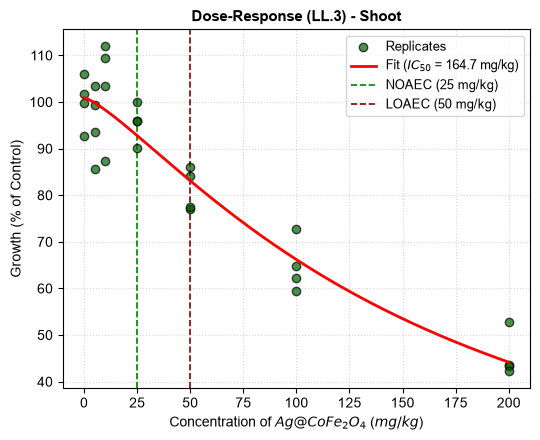


STAGE 3: TOXICOLOGICAL PROFILE - LL.3 & DUNNETT (ROOT)
📋 Dunnett's Test Statistical Thresholds:
   • NOAEC (No Observed Adverse Effect Concentration): 25.0 mg/kg
   • LOAEC (Lowest Observed Adverse Effect Concentration): 50.0 mg/kg ⚠️
   -------------------------------------------------
✅ Successful Mathematical Fit for Root:
   • Control Growth (Top)  : 120.00 ± 7.64 %
   • Phytotoxicity (IC50)  : 44.68 ± 7.86 mg/kg 🎯
   • Hill Slope Coefficient: 1.69 ± 0.43
   • R-squared (R²)        : 0.8150


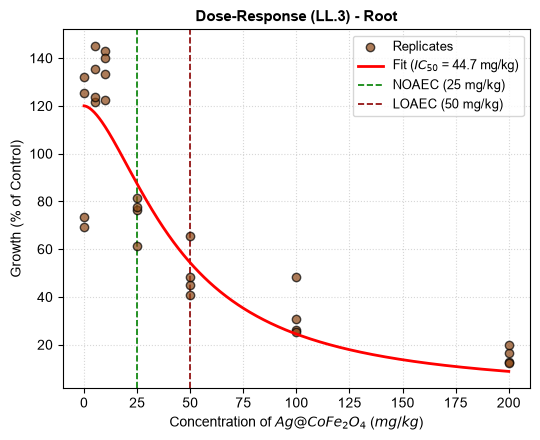

In [5]:
def log_logistic_3p(dose, top, ic50, hill_slope):
    """Standard Log-Logistic 3-Parameter Model (LL.3)"""
    return top / (1 + (dose / ic50) ** hill_slope)

def fit_dose_response(df_organ, organ_name):
    print(f"\n==================================================")
    print(f"STAGE 3: TOXICOLOGICAL PROFILE - LL.3 & DUNNETT ({organ_name.upper()})")
    print(f"==================================================")
    
    df_fit = df_organ.dropna(subset=['Growth'])
    X = df_fit['Dose'].values
    Y = df_fit['Growth'].values
    
    # 3.1 Dunnett's Test for Regulatory Thresholds
    control_growth = df_fit[df_fit['Dose'] == 0]['Growth'].values
    exposed_doses = sorted([d for d in df_fit['Dose'].unique() if d > 0])
    
    noaec_val = 0.0
    loaec_val = None
    doses_data = [df_fit[df_fit['Dose'] == dose]['Growth'].values for dose in exposed_doses]
    
    try:
        res_dunnett = dunnett(*doses_data, control=control_growth, alternative='less')
        p_values = res_dunnett.pvalue
        
        for idx, dose in enumerate(exposed_doses):
            if p_values[idx] < 0.05:
                loaec_val = float(dose)
                if idx > 0:
                    noaec_val = float(exposed_doses[idx-1])
                break
        else:
            noaec_val = float(exposed_doses[-1])
            
        print(f"📋 Dunnett's Test Statistical Thresholds:")
        print(f"   • NOAEC (No Observed Adverse Effect Concentration): {noaec_val} mg/kg")
        print(f"   • LOAEC (Lowest Observed Adverse Effect Concentration): {f'{loaec_val} mg/kg' if loaec_val else 'No significant effect'} ⚠️")
        print("   -------------------------------------------------")
    except Exception as dun_err:
        print(f"ℹ️ Dunnett's test skipped or needs replication check: {dun_err}")

    # 3.2 Non-Linear Optimization & Curve Fitting
    p0 = [100.0, np.median(X), 1.0]
    try:
        popt, pcov = curve_fit(log_logistic_3p, X, Y, p0=p0, bounds=(0, [120, np.inf, np.inf]))
        top, ic50, slope = popt
        
        # Correctly extract individual standard errors as floats
        perr = np.sqrt(np.diag(pcov))
        top_err = float(perr[0])
        ic50_err = float(perr[1])
        slope_err = float(perr[2])
        
        residuals = Y - log_logistic_3p(X, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((Y - np.mean(Y))**2)
        r_squared = 1 - (ss_res / ss_tot)
        
        print(f"✅ Successful Mathematical Fit for {organ_name.capitalize()}:")
        print(f"   • Control Growth (Top)  : {top:.2f} ± {top_err:.2f} %")
        print(f"   • Phytotoxicity (IC50)  : {ic50:.2f} ± {ic50_err:.2f} mg/kg 🎯")
        print(f"   • Hill Slope Coefficient: {slope:.2f} ± {slope_err:.2f}")
        print(f"   • R-squared (R²)        : {r_squared:.4f}")
        
        # --- Visualization Generation ---
        plt.figure(figsize=(5.5, 4.5))
        dot_color = 'darkgreen' if organ_name == 'shoot' else 'saddlebrown'
        
        plt.scatter(X, Y, color=dot_color, label='Replicates', alpha=0.7, edgecolors='black', zorder=3)
        x_curve = np.linspace(0, max(X), 500)
        plt.plot(x_curve, log_logistic_3p(x_curve, *popt), 'r-', linewidth=2, label=f'Fit ($IC_{{50}}$ = {ic50:.1f} mg/kg)', zorder=4)
        
        plt.axvline(x=noaec_val, color='green', linestyle='--', linewidth=1.2, label=f'NOAEC ({noaec_val:.0f} mg/kg)', zorder=2)
        if loaec_val is not None:
            plt.axvline(x=loaec_val, color='darkred', linestyle='--', linewidth=1.2, label=f'LOAEC ({loaec_val:.0f} mg/kg)', zorder=2)
        
        plt.title(f'Dose-Response (LL.3) - {organ_name.capitalize()}', fontsize=11, fontweight='bold')
        plt.xlabel(r'Concentration of $Ag@CoFe_2O_4$ ($mg/kg$)')
        plt.ylabel('Growth (% of Control)')
        plt.grid(True, linestyle=':', alpha=0.5, zorder=1)
        plt.legend(fontsize=9, loc='upper right')
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"❌ Curve fitting failed for {organ_name}: {e}")

# Run modeling engines
fit_dose_response(df_shoot, "shoot")
fit_dose_response(df_root, "root")


## Stage 4: Multivariate Physiological Dynamics & PCA Biplot
This final stage evaluates the interactive relationships between internalized metal pressures (`Fe`, `Co`, `Ag`) and the crop's physiological metrics: photosynthetic pigments (`Chla`, `Chlb`, `Chltot`, `Car`) and the protective antioxidant machinery (`CAT`, `APX`, `GPX`, `SOD`). 

All datasets are automatically standardized to unit variance before executing a dimensional reduction via **Principal Component Analysis (PCA)**. The results are visualized using a **Biplot graph**, illustrating sample behavior groupings mapped alongside directional variable loading vectors.



STAGE 4: PHYSIOLOGICAL ANALYSIS (SHOOT)
📋 Pearson Correlation Coefficients (r) against Metal Burdens:
    Growth   Chla   Chlb  Chltot    Car   Prot    CAT    APX    GPX    SOD
Fe  -0.124 -0.048  0.001  -0.035  0.012  0.057  0.007 -0.038  0.032  0.200
Co  -0.442 -0.017  0.095   0.013  0.105  0.063  0.029  0.062  0.020  0.418
Ag  -0.673  0.059  0.206   0.099  0.219  0.086  0.127  0.023  0.109  0.559


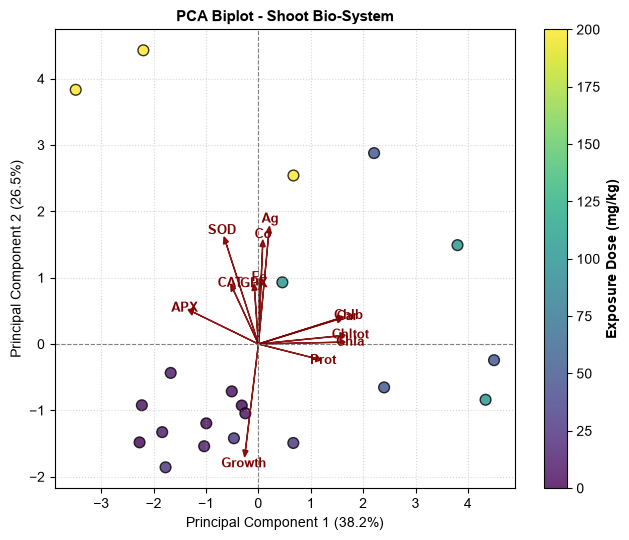


STAGE 4: PHYSIOLOGICAL ANALYSIS (ROOT)
📋 Pearson Correlation Coefficients (r) against Metal Burdens:
    Growth   Prot    CAT    APX    GPX    SOD
Fe  -0.356  0.354  0.054 -0.108 -0.296 -0.189
Co  -0.481  0.339  0.141 -0.153 -0.333 -0.369
Ag  -0.695  0.549  0.064  0.004 -0.260 -0.299


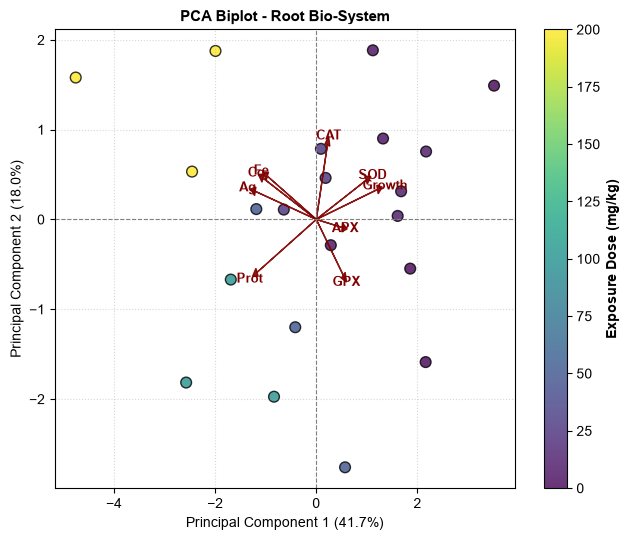

In [9]:
def analyze_physiological_response(df_organ, organ_name):
    print(f"\n==================================================")
    print(f"STAGE 4: PHYSIOLOGICAL ANALYSIS ({organ_name.upper()})")
    print(f"==================================================")
    
    # 1. Master array declaration of potential features
    pca_features = ['Fe', 'Co', 'Ag', 'Growth', 'Chla', 'Chlb', 'Chltot', 'Car', 'Prot', 'CAT', 'APX', 'GPX', 'SOD']
    
    # FIX: Dynamically retain columns ONLY if they exist AND contain at least one valid measurement for this specific organ
    active_pca_features = [f for f in pca_features if f in df_organ.columns and df_organ[f].notna().any()]
    
    # Include 'Dose' for mapping color codes on the right axis scale
    all_features = ['Dose'] + active_pca_features
    df_sub = df_organ[all_features].dropna()
    
    if len(df_sub) < 3:
        print(f"⚠️ Insufficient observation matrix rows to perform the PCA projection for {organ_name}.")
        return
        
    # 2. Pearson Correlation Coefficients Matrix
    valid_metals = [m for m in metals if m in df_sub.columns]
    valid_targets = [t for t in active_pca_features if t not in valid_metals]
    corr_matrix = df_sub[active_pca_features].corr()
    print("📋 Pearson Correlation Coefficients (r) against Metal Burdens:")
    print(corr_matrix.loc[valid_metals, valid_targets].round(3))
    
    # 3. Z-Score Standardization & PCA (Strictly excluding 'Dose' from variance computation)
    X_matrix = df_sub[active_pca_features].values
    X_scaled = StandardScaler().fit_transform(X_matrix)
    
    pca = PCA(n_components=2)
    pca_scores = pca.fit_transform(X_scaled)
    loadings = pca.components_.T
    
    # 4. Publication-Quality Rendering (Perfect match with your original layout)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    
    # Scatter points colored by continuous dosage gradient
    scatter = ax.scatter(pca_scores[:, 0], pca_scores[:, 1], c=df_sub['Dose'], 
                         cmap='viridis', edgecolors='k', alpha=0.8, s=60)
    
    # Map vector projection loading paths in maroon
    for i, feature in enumerate(active_pca_features):
        ax.arrow(0, 0, loadings[i, 0]*max(pca_scores[:,0])*0.8, loadings[i, 1]*max(pca_scores[:,1])*0.8, 
                  color='maroon', alpha=0.9, head_width=0.1, head_length=0.1)
        ax.text(loadings[i, 0]*max(pca_scores[:,0])*0.9, loadings[i, 1]*max(pca_scores[:,1])*0.9, 
                 feature, color='maroon', ha='center', va='center', fontweight='bold', fontsize=9)
        
    ax.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(f'PCA Biplot - {organ_name.capitalize()} Bio-System', fontsize=11, fontweight='bold')
    
    # Force the continuous Exposure Dose colorbar exactly on the right side
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label('Exposure Dose (mg/kg)', fontweight='bold')
        
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='grey', linestyle='--', linewidth=0.8)
    plt.tight_layout()
    plt.show()

# Parallel execution for both vegetative fractions
analyze_physiological_response(df_shoot, "shoot")
analyze_physiological_response(df_root, "root")


### 💡 Technical Note on PCA Vector Orientation (Sign Flipping Effect)

When executing Principal Component Analysis (PCA) across different environments or computational runs, you may observe a **180-degree rotation or mirror reflection** in the orientation of the axes, vectors, and sample distribution compared to previous software runs. 

**This behavior is entirely correct and mathematically expected due to a standard property known as "Sign Flipping."**

*   **The Analogy of a Molecule:** Think of this projection exactly like viewing a **3D molecule**. If you rotate a molecule or look at its perfect mirror image in space, the geometry, bond lengths, and relative positions of its atoms remain completely unchanged. The molecule's physical and chemical reality is identical; only your visual perspective has changed.
*   **The Coordinate System:** In PCA, the decomposition algorithm calculates axes based on maximum variance. Mathematically, if a directional vector \(V\) is a valid solution, its exact opposite vector \(-V\) is equally valid and captures the identical amount of variance. The negative or positive signs on the coordinate axes are simply spatial benchmarks, not absolute values indicating "increase" or "decrease."
*   **Biological Invariance:** The biological interpretation of this system is strictly invariant to reflections. 
    1. **Vector Angles:** The angles between the crimson arrows remain identical, preserving the same Pearson correlation structures (e.g., the strong negative correlation between `Growth` and `Ag` accumulation).
    2. **Point-to-Vector Clustered Proximities:** Low-exposure control replicates will always group on the side towards which the `Growth` vector points, whereas high-exposure treatments will remain clustered on the opposite side of the vector path.

Therefore, both orientations represent the **exact same physiological data system** and yield identical ecotoxicological conclusions.


## 🔬 Conclusions and Critical Modeling Inferences

Based on the computational workflow implemented across the shoot and root datasets of wheat seedlings exposed to $\text{Ag@CoFe}_2\text{O}_4$ NPs, the following conclusions can be drawn:

### 1. Ecotoxicological Thresholding & Dunnett's Parameters
*   Through the integration of the many-to-one **Dunnett's post-hoc test**, the **LOAEC** (Lowest Observed Adverse Effect Concentration) was strictly defined as the **very first tested dosage that was statistically lower than the unamended control group (0 mg/kg)** at a significance level of p < 0.05. 
*   This mathematical filter automatically isolated the definitive regulatory tipping point where toxic pressure significantly impairs elongation, establishing a rigorous safety boundary (**NOAEC**) right below it.

### 2. Dose-Response Modeling Assumptions (Toxic vs. Hormetic Effects)
*   The non-linear regression curve was successfully mapped using a standard **3-Parameter Log-Logistic Model (LL.3)** to compute the median inhibitory concentration ($IC_{50}$). 
*   **Crucial Modeling Limitation:** It must be highlighted that this mathematical setup focused exclusively on mapping monotonic decay. Consequently, **the model did not segregate or mathematically isolate low-dose biostimulatory (hormetic) responses from full-scale toxic constraints**. 
*   As recorded in the root assays (where concentrations of 5 and 10 mg/kg induced structural enhancement), the LL.3 model treats these deviations as standard data variance rather than fitting an independent biphasic sub-equation (such as the Brain-Cousens model). Therefore, the resulting $IC_{50}$ parameter represents a conservative, purely toxicological index.

### 3. Multivariate System Biomarkers
*   The standardized **PCA Biplot** confirmed that the physiological machinery reacts as a coupled network under $\text{Ag@CoFe}_2\text{O}_4$ stress. 
*   The sharp spatial opposition (near $180^\circ$ angle) between the `Growth` vector and the elemental loading vectors (`Ag`, `Co`, `Fe`) corroborates that intracellular metal burden is the primary operational driver forcing both the decay in elongation and the concurrent mobilization of the antioxidant enzymatic array (`CAT`, `APX`, `GPX`, `SOD`).
